# Predicting house prices in Bromley, Croydon and Greenwich

The question: using only what's in the Land Registry record, how well can Linear Regression and a Random Forest predict what a home sells for in these three boroughs? And how much do finer location and tuning buy over just looking up a median, when they're tested on later sales they've never seen?

I'm building on three published comparisons.
- Mathotaarachchi et al. (2024): Linear Regression, Random Forest and boosting on UK Land Registry sales, checked on a second dataset.
- Mora-García et al. (2022): Random Forest and boosting against a Linear Regression baseline, on listings in Alicante, Spain.
- Ho et al. (2021): a support vector machine, Random Forest and gradient boosting on about 40,000 Hong Kong sales. No Linear Regression in that one, so I only lean on it for the tree models.

What I add to the LR vs RF comparison:
- testing on *later* sales, which is how a valuation model actually gets used
- two median baselines to beat
- a postcode-location ablation
- RF tuning, with bootstrap intervals on the gains

Sections: 0 setup · 1 load · 2 clean · 3 features · 4 split · 5 baselines (R1-R2) · 6 LR / RF on validation (R3-R6) · 7 RF tuning (R7) · 8 final test · 9 errors · 10 bootstrap / seeds / importance · 11 follow-ups (E1-E6) · 12 save

Data: HM Land Registry Price Paid Data 2024 + 2025. Contains HM Land Registry data © Crown copyright and database right 2021. This data is licensed under the Open Government Licence v3.0.

## 0. Setup

In [1]:
import os
import shutil
import sys
import urllib.request

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error, root_mean_squared_error,
                             r2_score, mean_absolute_percentage_error)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42          # same seed everywhere
DATA_DIR = "data/raw"      # Land Registry files, downloaded on first run
RAW_URL = "https://price-paid-data.publicdata.landregistry.gov.uk"

# the London Datastore 403'd python's default client name in the floor-area notebook. same name here
USER_AGENT = "Mozilla/5.0 (compatible; house-price-ml research notebook)"
RESULTS_DIR = "results"    # all tables + figures
BOROUGHS = ["BROMLEY", "CROYDON", "GREENWICH"]

os.makedirs(RESULTS_DIR, exist_ok=True)

# versions, so the results can be tied to an environment
print("python", sys.version.split()[0], "| pandas", pd.__version__,
      "| numpy", np.__version__, "| sklearn", sklearn.__version__)

python 3.13.18 | pandas 3.1.1 | numpy 2.5.4 | sklearn 1.9.1


## 1. Load the data
No header row in the yearly files. The GOV.UK guide lists 15 columns, plus a 16th (*record status*) that it says is only in the monthly files. The yearly files I downloaded in November 2026 have it anyway, "A" on every row, and when I checked the first line of both official files again on 18 November there were still 16. So the loader takes either 15 or 16 columns, checks the count first, and only reads what it needs.

If the files aren't in `data/raw/` it downloads them. Over 100 MB each, so the first run is slower.

In [2]:
# file order, no header. record_status is the 16th; a 15-column file just stops at ppd_category
COLS = ["transaction_id", "price", "date", "postcode", "property_type", "old_new",
        "duration", "paon", "saon", "street", "locality", "town_city",
        "district", "county", "ppd_category", "record_status"]

# the ones I use
KEEP = ["transaction_id", "price", "date", "postcode", "property_type",
        "old_new", "duration", "district", "ppd_category"]

def download(url, path):
    request = urllib.request.Request(url, headers={"User-Agent": USER_AGENT})
    # .part first, so a cut-off download never looks finished
    with urllib.request.urlopen(request) as response, open(path + ".part", "wb") as f:
        shutil.copyfileobj(response, f, length=1024 * 1024)
    os.replace(path + ".part", path)

def raw_file(year):
    # downloaded the first time it's needed
    path = f"{DATA_DIR}/pp-{year}.csv"
    if not os.path.exists(path):
        os.makedirs(DATA_DIR, exist_ok=True)
        print(f"downloading pp-{year}.csv (over 100 MB, give it a few minutes)...")
        download(f"{RAW_URL}/pp-{year}.csv", path)
    return path

def load_ppd(year):
    path = raw_file(year)

    # check the column count on 5 rows before reading 100 MB+
    n_cols = pd.read_csv(path, header=None, nrows=5).shape[1]
    assert n_cols in (15, 16), f"{path}: expected 15 or 16 columns, got {n_cols}"

    df = pd.read_csv(path, header=None, names=COLS[:n_cols], usecols=KEEP, dtype=str)
    df["price"] = df["price"].astype(int)
    df["date"] = pd.to_datetime(df["date"])
    return df

raw = pd.concat([load_ppd(2024), load_ppd(2025)], ignore_index=True)
print(raw.shape)
print(raw["date"].min(), "->", raw["date"].max())

# how are the borough names spelt? check before filtering on them
is_ours = raw["district"].str.contains("BROMLEY|CROYDON|GREENWICH")
print(raw.loc[is_ours, "district"].unique())

(1924492, 9)
2024-01-01 00:00:00 -> 2025-12-31 00:00:00


<StringArray>
['CROYDON', 'BROMLEY', 'GREENWICH']
Length: 3, dtype: str


## 2. Cleaning
No rule looks at the price.

In [3]:
POSTCODE_RE = r"^[A-Z]{1,2}[0-9][A-Z0-9]? [0-9][A-Z]{2}$"   # e.g. "BR3 3JW"
steps = []

def log_step(name, d):
    # rows left per year after each rule, in case one rule hits one year harder
    per_year = d["date"].dt.year.value_counts()
    steps.append({"step": name, "2024": per_year.get(2024, 0),
                  "2025": per_year.get(2025, 0), "total": len(d)})

df = raw.copy()
log_step("raw file (England & Wales)", df)

df = df[df["district"].isin(BOROUGHS)]
log_step("district in 3 boroughs", df)

# A = ordinary sales. B = repossessions, buy-to-let, company buyers etc.
df = df[df["ppd_category"] == "A"]
log_step("category A (standard sales)", df)

# type "O" only shows up in category B, so this removes 0 rows here. kept it so it's written down
df = df[df["property_type"].isin(["D", "S", "T", "F"])]
log_step("type D/S/T/F (drop 'O')", df)

df = df.drop_duplicates("transaction_id")
log_step("no duplicate IDs", df)

df = df[df["postcode"].fillna("").str.match(POSTCODE_RE)]
log_step("valid postcode", df)

data_quality = pd.DataFrame(steps)
data_quality["removed"] = (-data_quality["total"].diff()).fillna(0).astype(int)
data_quality

,step,2024,2025,total,removed
0,raw file (England & Wales),932214,992278,1924492,0
1,district in 3 boroughs,13484,13880,27364,1897128
2,category A (standard sales),10835,11336,22171,5193
3,type D/S/T/F (drop 'O'),10835,11336,22171,0
4,no duplicate IDs,10835,11336,22171,0
5,valid postcode,10835,11335,22170,1


In [4]:
assert set(df["district"]) == set(BOROUGHS)
assert set(df["ppd_category"]) == {"A"}
assert set(df["property_type"]) <= {"D", "S", "T", "F"}

# the plan allowed trimming extreme prices from training. didn't need it:
# the £100-type transfers were all category B, already gone
print(df["price"].describe().round(0))

count      22170.0
mean      527460.0
std       299443.0
min        80000.0
25%       350000.0
50%       464450.0
75%       625000.0
max      6480000.0
Name: price, dtype: float64


## 3. Features
Explaining a price by the home's attributes is the hedonic idea (Rosen, 1974).
- **F0 (basic):** property type, new build, tenure, borough, month of sale
- **F1 (+location):** F0 + postcode district (BR3, SE10...)
- **F2 (+finer location):** F1 + postcode sector (BR3 3). Only in the section 11 follow-ups.

No street or house number. Thousands of values, the model would basically memorise addresses.

In [5]:
df["borough"] = df["district"].str.title()               # "BROMLEY" -> "Bromley"
df["sale_month"] = df["date"].dt.month                   # 1 to 12
df["postcode_district"] = df["postcode"].str.split().str[0]   # "BR3 3JW" -> "BR3"

df["postcode_sector"] = df["postcode"].str[:-2]               # "BR3 3JW" -> "BR3 3"

F0 = ["property_type", "old_new", "duration", "borough", "sale_month"]
F1 = F0 + ["postcode_district"]
F2 = F1 + ["postcode_sector"]      # only used in the follow-up experiments (section 11)

print(df["postcode_district"].nunique(), "postcode districts,",
      df["postcode_sector"].nunique(), "postcode sectors")
df[F1 + ["price"]].head()

35 postcode districts, 109 postcode sectors


,property_type,old_new,duration,borough,sale_month,postcode_district,price
0,D,N,F,Croydon,8,CR0,575000
1,S,N,F,Bromley,8,SE20,1300000
2,T,N,F,Greenwich,5,SE3,905000
3,S,N,F,Croydon,12,CR8,752000
4,T,N,F,Bromley,12,BR7,905000


## 4. Temporal split
Train = 2024, validation = Jan-Jun 2025 (only for choosing settings), test = Jul-Dec 2025, used **once** at the end.

In [6]:
train = df[df["date"].dt.year == 2024]
val   = df[(df["date"] >= "2025-01-01") & (df["date"] < "2025-07-01")]
test  = df[df["date"] >= "2025-07-01"]

# no overlap, every row in exactly one split
assert train["date"].max() < val["date"].min()
assert val["date"].max() < test["date"].min()
assert len(train) + len(val) + len(test) == len(df)

# every 2025 sale is in val or test, nothing dropped for its price
assert len(val) + len(test) == (df["date"].dt.year == 2025).sum()

split_sizes = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "period": ["2024", "Jan-Jun 2025", "Jul-Dec 2025"],
    "rows": [len(train), len(val), len(test)],
    "median price": [part["price"].median() for part in (train, val, test)]})
split_sizes

,split,period,rows,median price
0,train,2024,10835,460000.0
1,validation,Jan-Jun 2025,5730,465000.0
2,test,Jul-Dec 2025,5605,470000.0


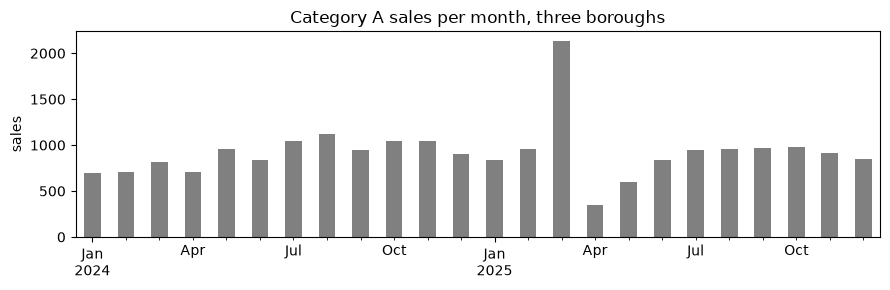

In [7]:
# sales per month. two things to look for:
#  - a drop at the end of 2025 (sales can take months to reach the Land Registry)
#  - a rush in March 2025, before the stamp duty thresholds changed on 1 April
monthly = df.groupby(df["date"].dt.to_period("M")).size()

ax = monthly.plot(kind="bar", figsize=(9, 3), color="grey")
ax.set_ylabel("sales")
ax.set_xlabel("")
ax.set_title("Category A sales per month, three boroughs")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/fig_monthly_counts.png", dpi=150)
plt.show()

## 5. Baselines (R1, R2)
If a model can't beat these, it isn't adding anything.

In [8]:
def global_median(train_df, test_df):
    # R1: guess the same price for every house, the median of the training sales
    return np.full(len(test_df), train_df["price"].median())

def group_median(train_df, test_df):
    # R2: guess the median price of the same borough and property type.
    # a simple comparable-sales proxy, not a real comparables valuation.
    # if a borough/type pair never appears in training, use the overall median instead
    keys = ["borough", "property_type"]
    medians = train_df.groupby(keys)["price"].median().rename("pred").reset_index()
    pred = test_df[keys].merge(medians, on=keys, how="left")["pred"]
    return pred.fillna(train_df["price"].median()).to_numpy()

# check both baselines on a tiny example where I can work the medians out by hand
toy_train = pd.DataFrame({"borough": ["A", "A", "A", "B"],
                          "property_type": ["F", "F", "D", "F"],
                          "price": [100, 200, 900, 50]})
toy_test = pd.DataFrame({"borough": ["A", "B", "B"], "property_type": ["F", "F", "D"]})

assert list(global_median(toy_train, toy_test)) == [150, 150, 150]
assert list(group_median(toy_train, toy_test)) == [150, 50, 150]   # (B, D) isn't in training -> overall median

## 6. Linear Regression and Random Forest (R3-R6)
scikit-learn (Pedregosa et al., 2011). Random Forest is Breiman's (2001) method.
One pipeline per run: one-hot encode, model, log of the target. `handle_unknown="ignore"` means a postcode district the model never saw just gets all zeros.

In [9]:
def make_model(model, features, log_target=True):
    # one-hot the features, learn log(price), predict back in £
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    prep = ColumnTransformer([("onehot", onehot, features)])
    pipe = Pipeline([("prep", prep), ("model", model)])
    if log_target:
        return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)
    # raw price, only for the section 11 log-vs-raw test
    return TransformedTargetRegressor(regressor=pipe)

def scores(y_true, y_pred):
    # the four from the plan, MAE is the main one
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": root_mean_squared_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred),
            "MAPE %": 100 * mean_absolute_percentage_error(y_true, y_pred)}

def rf(seed=RANDOM_STATE, **params):
    # 300 trees: stable enough, still fits in seconds
    return RandomForestRegressor(n_estimators=300, random_state=seed, n_jobs=-1, **params)

# run names in one place so the tables and the code can't drift apart
R1 = "R1 Global median"
R2 = "R2 Group median (borough x type)"
R3 = "R3 LinearRegression F0"
R4 = "R4 RandomForest F0"
R5 = "R5 LinearRegression F1"
R6 = "R6 RandomForest F1"
R7 = "R7 Tuned RandomForest F1"

# model + feature set per run. R7 gets added after tuning.
# these are templates, sklearn takes a fresh copy each fit
ml_runs = {
    R3: (LinearRegression(), F0),
    R4: (rf(), F0),
    R5: (LinearRegression(), F1),
    R6: (rf(), F1),
}

In [10]:
def run_all(fit_df, eval_df, runs):
    # fit each run on fit_df, score on eval_df. baselines first
    preds = {R1: global_median(fit_df, eval_df),
             R2: group_median(fit_df, eval_df)}
    models = {}
    for name, (model, feats) in runs.items():
        models[name] = make_model(model, feats).fit(fit_df[feats], fit_df["price"])
        preds[name] = models[name].predict(eval_df[feats])

    rows = [{"run": name, **scores(eval_df["price"], pred)} for name, pred in preds.items()]
    return pd.DataFrame(rows).set_index("run"), preds, models

val_results, _, _ = run_all(train, val, ml_runs)
val_results.round(3)

,MAE,RMSE,R2,MAPE %
run,,,,
R1 Global median,186601.810,306140.305,-0.052,38.060
R2 Group median (borough x type),134553.162,237661.891,0.366,26.080
R3 LinearRegression F0,135776.441,235132.305,0.379,25.973
R4 RandomForest F0,137494.704,237800.525,0.365,26.222
R5 LinearRegression F1,123404.828,218203.506,0.465,23.842
R6 RandomForest F1,128260.369,224593.380,0.434,24.558


In [11]:
# did the encoder only learn categories from the training rows?
m = make_model(LinearRegression(), F1).fit(train[F1], train["price"])
encoder = m.regressor_.named_steps["prep"].named_transformers_["onehot"]
learnt_districts = set(encoder.categories_[F1.index("postcode_district")])
assert learnt_districts == set(train["postcode_district"])

later_districts = set(val["postcode_district"]) | set(test["postcode_district"])
print("districts only in validation/test (encoded as all zeros):",
      sorted(later_districts - learnt_districts))

districts only in validation/test (encoded as all zeros): []


## 7. Random Forest tuning (R7)
Tuned on the validation months, not cross-validation. Random folds would mix 2024 and 2025 sales together, which defeats the point of the split.
- `min_samples_leaf`: how many sales each leaf averages over. Bigger = smoother.
- `max_features`: how many features each split gets to look at. 1.0 = all of them, "sqrt" = a random subset.

`max_depth` stays at None since the leaf size already limits depth. 4 x 2 = 8 settings. Two settings within £100 of each other on validation count as tied, and then I take the bigger leaf.

In [12]:
TIE_TOLERANCE = 100   # £. this close on val MAE = tied

tuning_rows = []
for leaf in [1, 5, 10, 20]:
    for max_feat in [1.0, "sqrt"]:
        m = make_model(rf(min_samples_leaf=leaf, max_features=max_feat), F1)
        m.fit(train[F1], train["price"])
        tuning_rows.append({
            "min_samples_leaf": leaf,
            "max_features": max_feat,
            "train MAE": mean_absolute_error(train["price"], m.predict(train[F1])),
            "val MAE": mean_absolute_error(val["price"], m.predict(val[F1]))})

tuning = pd.DataFrame(tuning_rows)
tuning["gap"] = tuning["val MAE"] - tuning["train MAE"]   # big gap = overfitting

# lowest val MAE. ties -> biggest leaf (simpler model)
tied = tuning[tuning["val MAE"] <= tuning["val MAE"].min() + TIE_TOLERANCE]
best = tied.sort_values(["min_samples_leaf", "val MAE"], ascending=[False, True]).iloc[0]
best_params = {"min_samples_leaf": int(best["min_samples_leaf"]),
               "max_features": best["max_features"]}

print("chosen:", best_params)
tuning.round(0)

chosen: {'min_samples_leaf': 5, 'max_features': 'sqrt'}


,min_samples_leaf,max_features,train MAE,val MAE,gap
0,1,1.0,109365.0,128260.0,18895.0
1,1,sqrt,109351.0,128176.0,18825.0
2,5,1.0,114273.0,123785.0,9512.0
3,5,sqrt,116888.0,121332.0,4444.0
4,10,1.0,117064.0,122160.0,5096.0
5,10,sqrt,119665.0,121623.0,1958.0
6,20,1.0,120222.0,122582.0,2360.0
7,20,sqrt,122600.0,123020.0,420.0


## 8. Final test (run once)
Every run, R1-R7, refitted on train + validation the same way, then scored on Jul-Dec 2025. Refitting also means they've all seen the post-April 2025 market.

In [13]:
final_runs = {**ml_runs, R7: (rf(**best_params), F1)}

train_val = pd.concat([train, val])
test_results, test_preds, final_models = run_all(train_val, test, final_runs)
test_results.round(3)

,MAE,RMSE,R2,MAPE %
run,,,,
R1 Global median,189807.286,297930.362,-0.062,39.361
R2 Group median (borough x type),138522.994,228251.765,0.377,27.496
R3 LinearRegression F0,138613.454,224212.564,0.399,27.416
R4 RandomForest F0,138105.492,225927.603,0.389,27.385
R5 LinearRegression F1,124467.983,207836.192,0.483,24.761
R6 RandomForest F1,126350.692,212740.695,0.459,25.123
R7 Tuned RandomForest F1,121839.398,206945.683,0.488,24.245


In [14]:
# headline comparisons, from the table rather than by eye
mae = test_results["MAE"]

def gain(worse, better):
    # £ of MAE the second run saves
    return mae[worse] - mae[better]

best_ml = mae.drop([R1, R2]).idxmin()   # best of the ML runs, R3-R7

print(f"RF vs LR (F0):          {gain(R3, R4):+,.0f} £ MAE in RF's favour")
print(f"RF vs LR (F1):          {gain(R5, R6):+,.0f} £")
print(f"postcode gain, LR:      {gain(R3, R5):+,.0f} £")
print(f"postcode gain, RF:      {gain(R4, R6):+,.0f} £")
print(f"tuning gain (R6 -> R7): {gain(R6, R7):+,.0f} £")
print(f"best ML vs group median: {gain(R2, best_ml):+,.0f} £")

RF vs LR (F0):          +508 £ MAE in RF's favour
RF vs LR (F1):          -1,883 £
postcode gain, LR:      +14,145 £
postcode gain, RF:      +11,755 £
tuning gain (R6 -> R7): +4,511 £
best ML vs group median: +16,684 £


## 9. Error analysis (R7, tuned RF)
Where does it go wrong?

In [15]:
err = test.copy()
err["pred"] = test_preds[R7]
err["abs_err"] = (err["price"] - err["pred"]).abs()
err["ape %"] = 100 * err["abs_err"] / err["price"]     # error as % of price

def breakdown(col):
    # number of sales, typical price and average error for each group
    return err.groupby(col).agg(n=("price", "size"),
                                median_price=("price", "median"),
                                MAE=("abs_err", "mean"),
                                MAPE=("ape %", "mean")).round(0)

TYPE_NAMES = {"D": "Detached", "S": "Semi", "T": "Terraced", "F": "Flat"}
by_type = breakdown("property_type").rename(index=TYPE_NAMES)
by_borough = breakdown("borough")
display(by_type, by_borough)

,n,median_price,MAE,MAPE
property_type,,,,
Detached,677,802500.0,253686.0,27.0
Flat,2034,326750.0,89253.0,31.0
Semi,1244,585000.0,133202.0,20.0
Terraced,1650,475000.0,99346.0,18.0


,n,median_price,MAE,MAPE
borough,,,,
Bromley,2251,525000.0,139221.0,24.0
Croydon,2015,440000.0,93474.0,21.0
Greenwich,1339,460000.0,135305.0,30.0


In [16]:
# 10 worst. expensive detached houses and new builds?
columns = ["date", "postcode", "property_type", "old_new", "duration", "price", "pred", "abs_err"]
worst = err.nlargest(10, "abs_err")[columns]
worst.round({"pred": 0, "abs_err": 0})

,date,postcode,property_type,old_new,duration,price,pred,abs_err
13492,2025-10-08,BR6 8NT,D,N,F,5100000,882891.0,4217109.0
12093,2025-07-18,BR6 8NJ,D,N,F,3250000,797654.0,2452346.0
17568,2025-08-06,BR2 6EW,D,N,F,3310000,868866.0,2441134.0
11124,2025-07-16,BR6 6HN,D,N,F,3125000,797654.0,2327346.0
21829,2025-10-08,BR6 8NJ,D,N,F,3125000,882891.0,2242109.0
22134,2025-11-19,SE3 7AS,T,N,F,2700000,620629.0,2079371.0
16581,2025-08-29,BR6 7SL,D,N,F,2800000,865701.0,1934299.0
11029,2025-11-19,SE3 7BD,S,N,F,2550000,802930.0,1747070.0
11077,2025-11-25,CR8 3LG,D,N,F,2365000,785650.0,1579350.0
22133,2025-10-20,SE3 0PH,S,N,F,2250000,766085.0,1483915.0


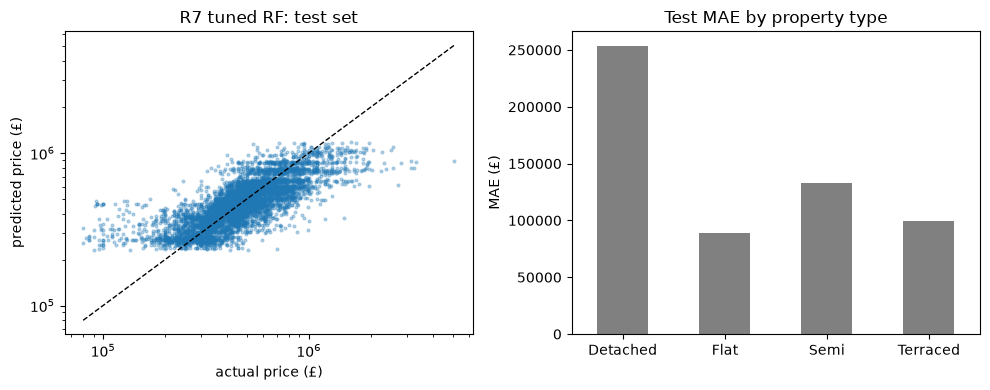

In [17]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))

# left: predicted vs actual. log axes or the few £3m+ sales squash everything
left.scatter(err["price"], err["pred"], s=4, alpha=0.3)
price_range = [err["price"].min(), err["price"].max()]
left.plot(price_range, price_range, "k--", lw=1)        # perfect = on the line
left.set_xscale("log")
left.set_yscale("log")
left.set_xlabel("actual price (£)")
left.set_ylabel("predicted price (£)")
left.set_title("R7 tuned RF: test set")

# right: average error for each property type
by_type["MAE"].plot(kind="bar", ax=right, color="grey")
right.set_ylabel("MAE (£)")
right.set_xlabel("")
right.set_title("Test MAE by property type")
right.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/fig_errors.png", dpi=150)
plt.show()

## 10. Are the differences real? (bootstrap, seeds, feature importance)
Some gaps in the table are only a few thousand pounds, so would they survive a different sample of test sales?

**Paired bootstrap:** resample the 5,605 test sales 1,000 times and recompute the MAE difference between two runs on the same resample each time. If the 95% interval misses 0, the gap is bigger than sampling noise in the test sales. It says nothing about what happens when the models are retrained.

In [18]:
rng = np.random.default_rng(RANDOM_STATE)
y = test["price"].to_numpy()
abs_err = {name: np.abs(y - pred) for name, pred in test_preds.items()}

# 1,000 resamples, the same ones for every comparison
boot_idx = rng.integers(0, len(y), size=(1000, len(y)))

def boot_diff(a, b):
    # MAE(a) - MAE(b), positive = b is better
    diff = abs_err[a] - abs_err[b]
    resampled = diff[boot_idx].mean(axis=1)
    low, high = np.percentile(resampled, [2.5, 97.5])
    return {"comparison": f"{a[:2]} - {b[:2]}", "MAE diff (£)": diff.mean(),
            "95% CI low": low, "95% CI high": high,
            "significant": not (low <= 0 <= high)}   # the interval doesn't cross zero

comparisons = [
    (R2, R7),   # does ML beat the group-median baseline?
    (R3, R4),   # LR vs RF on the basic features
    (R5, R7),   # LR vs the best RF
    (R3, R5),   # what postcode district adds for LR
    (R4, R6),   # what postcode district adds for RF
    (R6, R7),   # what tuning adds
]
bootstrap = pd.DataFrame([boot_diff(a, b) for a, b in comparisons])
bootstrap.round(0)

,comparison,MAE diff (£),95% CI low,95% CI high,significant
0,R2 - R7,16684.0,14794.0,18461.0,True
1,R3 - R4,508.0,-448.0,1436.0,False
2,R5 - R7,2629.0,1535.0,3761.0,True
3,R3 - R5,14145.0,12408.0,15756.0,True
4,R4 - R6,11755.0,9240.0,14078.0,True
5,R6 - R7,4511.0,3154.0,5795.0,True


In [19]:
# RF is random, so make sure it isn't one lucky seed: R6 and R7 with 5 seeds each,
# fitted on train + validation, scored on test
seed_rows = []
for seed in range(5):
    for name, params in [(R6, {}), (R7, best_params)]:
        m = make_model(rf(seed=seed, **params), F1)
        m.fit(train_val[F1], train_val["price"])
        seed_rows.append({"run": name, "seed": seed,
                          "test MAE": mean_absolute_error(y, m.predict(test[F1]))})

seeds = pd.DataFrame(seed_rows)
seeds.groupby("run")["test MAE"].agg(["mean", "std", "min", "max"]).round(0)

,mean,std,min,max
run,,,,
R6 RandomForest F1,126458.0,83.0,126367.0,126573.0
R7 Tuned RandomForest F1,122004.0,58.0,121940.0,122086.0


**Permutation importance:** shuffle one column of the test set at a time and see how much worse the MAE gets. Not the forest's built-in importance, because that favours features with lots of categories (Strobl et al., 2007), which here means postcode district. Shuffling isn't completely free of that either, so read it as a rough ranking. Done on the original columns, so each feature gets one score.

In [20]:
r7 = final_models[R7]
perm = permutation_importance(r7, test[F1], test["price"], scoring="neg_mean_absolute_error",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)

importance = pd.DataFrame({"feature": F1,
                           "MAE increase (£)": perm.importances_mean,
                           "sd": perm.importances_std})
importance = importance.sort_values("MAE increase (£)", ascending=False)
importance.round(0)

,feature,MAE increase (£),sd
0,property_type,46096.0,837.0
2,duration,38804.0,1076.0
5,postcode_district,22685.0,771.0
3,borough,9659.0,366.0
1,old_new,986.0,94.0
4,sale_month,-177.0,282.0


In [21]:
# where does postcode district help most? test MAE per borough: without it (R4), with it (R6), tuned (R7)
by_borough_gain = pd.DataFrame({
    name: test.assign(error=abs_err[name]).groupby("borough")["error"].mean()
    for name in [R4, R6, R7]}).round(0)
by_borough_gain["postcode gain (R4-R6)"] = by_borough_gain[R4] - by_borough_gain[R6]
by_borough_gain

,R4 RandomForest F0,R6 RandomForest F1,R7 Tuned RandomForest F1,postcode gain (R4-R6)
borough,,,,
Bromley,159449.0,145616.0,139221.0,13833.0
Croydon,99478.0,96282.0,93474.0,3196.0
Greenwich,160354.0,139213.0,135305.0,21141.0


## 11. Follow-up experiments (E1-E6)
R1-R7 are the planned comparison and stay the main result. Each of these changes **one** thing.

| Run | What changes | Question |
|---|---|---|
| E1 | The baseline uses postcode district x property type instead of borough x type | Is a more local "typical price" a tougher yardstick? |
| E2, E3 | LR and the tuned RF are also given the postcode sector (BR3 3) | Does even finer location help? |
| E4, E5 | LR and the tuned RF learn the price in pounds instead of log(price) | Is the log step actually helping? |
| E6 | Gradient boosting instead of Random Forest | Does a different kind of tree model do better? |

Same routine as R3-R7: fit on 2024 and score on validation, then refit on 2024 + Jan-Jun 2025 and score on test. 'gain' = pounds of average error saved against the planned run it's compared with. Below zero means worse.

I added these *after* seeing the R1-R7 test results, so treat them as a second look. The validation column is the fairer guide.

E6 is gradient boosting: trees built one after another, each one fixing the mistakes of the ones before. Ho et al. (2021) and Mora-García et al. (2022) both try it against Random Forest. scikit-learn's `HistGradientBoostingRegressor`, default settings.

In [22]:
def local_median(train_df, test_df, min_sales=10):
    # E1: like R2 but more local. the median price for the same postcode district and property type.
    # a group only counts if training has at least min_sales such sales, because a median of two
    # or three sales is too jumpy to trust. anything else gets R2's answer
    keys = ["postcode_district", "property_type"]
    groups = train_df.groupby(keys)["price"].agg(["median", "size"]).reset_index()
    groups = groups[groups["size"] >= min_sales]
    pred = test_df[keys].merge(groups, on=keys, how="left")["median"]
    return np.where(pred.isna(), group_median(train_df, test_df), pred)

# hand check: BR1 flats have 2 training sales (enough when min_sales=2), BR2 flats only have 1
toy_train = pd.DataFrame({"borough": ["A", "A", "A"],
                          "postcode_district": ["BR1", "BR1", "BR2"],
                          "property_type": ["F", "F", "F"],
                          "price": [100, 300, 900]})
toy_test = pd.DataFrame({"borough": ["A", "A"], "postcode_district": ["BR1", "BR2"],
                         "property_type": ["F", "F"]})

assert list(local_median(toy_train, toy_test, min_sales=2)) == [200, 300]   # BR2 falls back to the borough median

In [23]:
E1 = "E1 Local median (district x type)"
E2 = "E2 LinearRegression F2"
E3 = "E3 Tuned RandomForest F2"
E4 = "E4 LinearRegression F1, raw price"
E5 = "E5 Tuned RandomForest F1, raw price"
E6 = "E6 GradientBoosting F1"

# each extra is a model, a feature set, and whether it learns log(price) the way R3-R7 do
extra_runs = {
    E2: (LinearRegression(), F2, True),
    E3: (rf(**best_params), F2, True),
    E4: (LinearRegression(), F1, False),
    E5: (rf(**best_params), F1, False),
    E6: (HistGradientBoostingRegressor(random_state=RANDOM_STATE), F1, True),
}

def run_extras(fit_df, eval_df):
    # same idea as run_all: fit every extra on fit_df and predict eval_df
    preds = {E1: local_median(fit_df, eval_df)}
    for name, (model, feats, log_target) in extra_runs.items():
        fitted = make_model(model, feats, log_target).fit(fit_df[feats], fit_df["price"])
        preds[name] = fitted.predict(eval_df[feats])
    return preds

extra_val = run_extras(train, val)           # fit on 2024, predict Jan-Jun 2025
extra_test = run_extras(train_val, test)     # refit on 2024 + Jan-Jun 2025, predict Jul-Dec 2025

In [24]:
# line each extra up against the planned run it changes one thing about.
# E1 appears twice: against R2 (the old baseline) and against R7 (the best planned model),
# because the second one says whether machine learning beats a simple local lookup
comparisons = [(E1, R2), (E1, R7), (E2, R5), (E3, R7), (E4, R5), (E5, R7), (E6, R7)]

# validation MAE of the planned runs. R7's is the chosen row of the tuning table
val_mae = dict(val_results["MAE"])
val_mae[R7] = best["val MAE"]

rows = []
for name, ref in comparisons:
    abs_err[name] = np.abs(y - extra_test[name])     # so boot_diff from section 10 can use it
    ci = boot_diff(ref, name)                         # a positive gain means the extra is better
    extra_val_mae = mean_absolute_error(val["price"], extra_val[name])
    rows.append({"run": name, "compared with": ref[:2],
                 "val MAE": extra_val_mae, "val gain": val_mae[ref] - extra_val_mae,
                 "test MAE": abs_err[name].mean(), "test gain": ci["MAE diff (£)"],
                 "95% CI low": ci["95% CI low"], "95% CI high": ci["95% CI high"]})

extras = pd.DataFrame(rows).set_index("run")
extras.round(0)

,compared with,val MAE,val gain,test MAE,test gain,95% CI low,95% CI high
run,,,,,,,
E1 Local median (district x type),R2,120823.0,13730.0,122786.0,15737.0,13577.0,17789.0
E1 Local median (district x type),R7,120823.0,508.0,122786.0,-946.0,-2093.0,258.0
E2 LinearRegression F2,R5,116107.0,7298.0,116390.0,8078.0,6801.0,9538.0
E3 Tuned RandomForest F2,R7,114147.0,7184.0,113551.0,8289.0,7262.0,9395.0
"E4 LinearRegression F1, raw price",R5,130085.0,-6680.0,131366.0,-6898.0,-8025.0,-5809.0
"E5 Tuned RandomForest F1, raw price",R7,122828.0,-1496.0,124231.0,-2392.0,-3370.0,-1470.0
E6 GradientBoosting F1,R7,120506.0,826.0,120055.0,1784.0,1068.0,2501.0


**Log price or raw price?** Learning log(price) aims at the *typical* price, so it tends to come in low on the expensive homes. Learning pounds directly chases the *average*, which a handful of big sales can drag about.
The table splits the test sales into the top 10% by price and the rest. The last column is average prediction minus actual: below zero = runs low overall.

In [25]:
expensive = (test["price"] >= test["price"].quantile(0.9)).to_numpy()
all_test_preds = {**test_preds, **extra_test}

rows = []
for name in [R5, E4, R7, E5]:
    rows.append({"run": name,
                 "MAE, top 10% by price": abs_err[name][expensive].mean(),
                 "MAE, other 90%": abs_err[name][~expensive].mean(),
                 "MAPE %": 100 * (abs_err[name] / y).mean(),
                 "average prediction - actual (£)": (all_test_preds[name] - y).mean()})

log_vs_raw = pd.DataFrame(rows).set_index("run")
log_vs_raw.round(1)

,"MAE, top 10% by price","MAE, other 90%",MAPE %,average prediction - actual (£)
run,,,,
R5 LinearRegression F1,384804.0,95455.7,24.8,-29601.5
"E4 LinearRegression F1, raw price",347072.1,107327.4,27.5,-3917.3
R7 Tuned RandomForest F1,385633.8,92441.7,24.2,-30512.5
"E5 Tuned RandomForest F1, raw price",345176.1,99608.9,26.1,-2999.2


**Is the model falling behind the market?** The final models only know sales up to June 2025. If prices kept rising, the predictions should drift lower month by month. Median % error per month, so a few huge misses don't swamp it.

The proper fix would be a market-trend feature, but 18 months of history isn't enough to tell a trend from the normal seasonal pattern.

In [26]:
err["signed %"] = 100 * (err["pred"] - err["price"]) / err["price"]     # below 0 = predicted too low

drift = err.groupby(err["date"].dt.to_period("M"))["signed %"].agg(["size", "median"])
drift = drift.rename(columns={"size": "sales", "median": "median % error"})
drift.round(1)

,sales,median % error
date,,
2025-07,947,-1.6
2025-08,959,1.0
2025-09,966,-0.2
2025-10,976,0.7
2025-11,909,-0.5
2025-12,848,1.6


## 12. Save everything (tables, figures, trained model, processed data)

In [27]:
# tables
data_quality.to_csv(f"{RESULTS_DIR}/data_quality.csv", index=False)
split_sizes.to_csv(f"{RESULTS_DIR}/split_sizes.csv", index=False)
val_results.round(4).to_csv(f"{RESULTS_DIR}/metrics_validation.csv")
test_results.round(4).to_csv(f"{RESULTS_DIR}/metrics_test.csv")
tuning.round(1).to_csv(f"{RESULTS_DIR}/tuning.csv", index=False)
pd.concat({"property_type": by_type, "borough": by_borough}).to_csv(f"{RESULTS_DIR}/errors_by_group.csv")
bootstrap.round(1).to_csv(f"{RESULTS_DIR}/bootstrap_ci.csv", index=False)
seeds.to_csv(f"{RESULTS_DIR}/seeds.csv", index=False)
importance.round(1).to_csv(f"{RESULTS_DIR}/permutation_importance.csv", index=False)
by_borough_gain.to_csv(f"{RESULTS_DIR}/postcode_gain_by_borough.csv")
extras.round(1).to_csv(f"{RESULTS_DIR}/extra_experiments.csv")
log_vs_raw.round(1).to_csv(f"{RESULTS_DIR}/log_vs_raw_price.csv")
drift.round(2).to_csv(f"{RESULTS_DIR}/monthly_drift.csv")

# the tuned forest, so it can be reused without refitting
joblib.dump(r7, f"{RESULTS_DIR}/model_r7_tuned_rf.joblib", compress=3)

# cleaned 3-borough data. small enough to share (the raw files are 100 MB+ each)
os.makedirs("data/processed", exist_ok=True)
processed_cols = ["transaction_id", "price", "date", "postcode"] + F1
df[processed_cols].to_csv("data/processed/three_boroughs_2024_2025.csv", index=False)

print("saved to", RESULTS_DIR)

saved to results


## References
- HM Land Registry (2026) *Price Paid Data* (yearly files for 2024 and 2025, downloaded 15 November 2026). Contains HM Land Registry data © Crown copyright and database right 2021. This data is licensed under the Open Government Licence v3.0. https://www.gov.uk/government/statistical-data-sets/price-paid-data-downloads
- Breiman, L. (2001) Random Forests. *Machine Learning*, 45(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Ho, W.K.O., Tang, B.-S. and Wong, S.W. (2021) Predicting property prices with machine learning algorithms. *Journal of Property Research*, 38(1), 48–70. https://doi.org/10.1080/09599916.2020.1832558
- Mathotaarachchi, K.V., Hasan, R. and Mahmood, S. (2024) Advanced Machine Learning Techniques for Predictive Modeling of Property Prices. *Information*, 15(6), 295. https://doi.org/10.3390/info15060295
- Mora-García, R.-T., Céspedes-López, M.-F. and Pérez-Sánchez, V.R. (2022) Housing Price Prediction Using Machine Learning Algorithms in COVID-19 Times. *Land*, 11(11), 2100. https://doi.org/10.3390/land11112100
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M. and Duchesnay, É. (2011) Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12(85), 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html
- Rosen, S. (1974) Hedonic Prices and Implicit Markets: Product Differentiation in Pure Competition. *Journal of Political Economy*, 82(1), 34–55. https://doi.org/10.1086/260169
- Strobl, C., Boulesteix, A.-L., Zeileis, A. and Hothorn, T. (2007) Bias in random forest variable importance measures: Illustrations, sources and a solution. *BMC Bioinformatics*, 8, 25. https://doi.org/10.1186/1471-2105-8-25